# Selecting Metrics for Accessment of Integration and Mapping Quality

In this notebook we explore metrics for measuring the quality of batch integration and the retention of biological information. Specifically, we assess the stabilty of these metrics in response to changes in cell counts. We moreover explore which metrics could be calculated per cell cluster rather than on the full data.

The biological metrics include "cLISI","NMI","ARI","ASW" and "graph connectivity". Batch-integration quality metrics include "iLISI", "kBET" and "Graph connectivity" for the batch covariate "Study". We also perform Principal Component regression of the covariates "study","sample","sex","BMI" and "disease_status", to see to what extent each of these covariates explain variance in the data.

Ultimately, we want to exclude metrics that change in response to changes in cell numbers from this project, as we will compare integrations of datasets of differing cell counts (i.e. reference versus reference + query).</br>
To determine sensitivity to changes in cell numbers, we subsample the reference (Human Lung Cell Atlas core) at different proportions.

Before subsampling, we want to make sure the variance due to the subsampling itself is negligible. To that aim, we subsample 5 times using different seeds and look at the variance in metric scores among those 5 random samples.

At the end of this notebook, the usability of the metrics at cell cluster level rather than full data level, is assessed by looking at the code provided in https://github.com/theislab/scib/tree/main/scib/metrics, also concidering the practical usability in terms of usefulness of the results.

In [ ]:
#Corrections 28.07.2022
#Calculation on neighborhood graph added for Batch and Biometrics
#Sillouette: Added embed= X_Scanvi_emb as parameter instead of UMAP
#'LISI' added type_="KNN" to lisi and kBET

In [1]:
import numpy as np
import scanpy as sc
import pandas as pd
import anndata
import scipy
import matplotlib.pyplot as plt
from datetime import date, datetime
import scib
import tqdm
import milopy #need to instell manually from guít
import milopy.core as milo
import warnings

In case the required R packages aren't installed yet install them now:

In [3]:
#activating %%R in notebook
%load_ext rpy2.ipython

In [ ]:
%%R
##Installing R packages required for Milopy
if (!requireNamespace("BiocManager", quietly = TRUE))
    install.packages("BiocManager")
BiocManager::install("edgeR")
install.packages("statmod", dependencies = TRUE, INSTALL_opts = '--no-lock')

In [ ]:
%%R
#Installing packages required for scib.metrics.kbet
install.packages("remotes")
library(remotes)
remotes::install_github(repo = "theislab/kBET",dependencies = TRUE,upgrade = TRUE)

# General settings and workspace setup

In [2]:
warnings.filterwarnings("ignore") #ignore warnings to keep output clean
plt.rcParams['figure.figsize']=(8,8) #rescale figures
sc.settings.verbosity = 3

In [3]:
workspace = "../../workspace/mariam.lkandushi/metric_selection/"
data_path = "../../workspace/hlca_lisa.sikkema_malte.luecken/HLCA_reproducibility/data/HLCA_core_h5ads/HLCA_v1.h5ad"

In [4]:
today = date.today()

In [5]:
#set starting proportion for subsampling
start = 0.6
#set endpoint 
end= 1
#set step
step =0.1

In [6]:
data = sc.read(data_path)

In [7]:
print(data)

AnnData object with n_obs × n_vars = 584884 × 28527
    obs: 'sample', 'original_celltype_ann', 'study_long', 'study', 'last_author_PI', 'subject_ID', 'subject_ID_as_published', 'pre_or_postnatal', 'age_in_years', 'age_range', 'sex', 'ethnicity', 'mixed_ethnicity', 'smoking_status', 'smoking_history', 'BMI', 'known_lung_disease', 'condition', 'subject_type', 'cause_of_death', 'sample_type', 'anatomical_region_coarse', 'anatomical_region_detailed', 'tissue_dissociation_protocol', 'cells_or_nuclei', 'single_cell_platform', "3'_or_5'", 'enrichment', 'sequencing_platform', 'reference_genome_coarse', 'ensembl_release_reference_genome', 'cell_ranger_version', 'disease_status', 'fresh_or_frozen', 'cultured', 'cell_viability_%', 'comments', 'Processing_site', 'dataset', 'anatomical_region_level_1', 'anatomical_region_level_2', 'anatomical_region_level_3', 'anatomical_region_highest_res', 'age', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'ori

In [7]:
bio_metrics = ["clisi","nmi","ari","sillouette","graph_connect"]
batch_metrics=["iLisi","kBET","graph_connect"]
PCR_cov=['study',"sample","sex","BMI","disease_status"]
metrics=[]
metrics.extend(bio_metrics)
metrics.extend(batch_metrics)

# Metric selection

In [ ]:
#to confirm that the variance from the actual subsampling proceess is negligible 
#we compute the metrics on two subsamples with 5 different random seeds between 0 and 100
#then we compare the std to the absolute change between the two subsamples A nad B via abs(metric(A)-metric(B))/std 
#to see that changes between cell counts are at least 2 std and show significance 
#and are not attributable to the subsampling protocol

results_variance = np.zeros((5,2,8))

for i in tqdm.tqdm(range(5)):
    #compute a random seed for subsampling
    seed = np.random.randint(0, high=100, size=None, dtype=int)
    
    #first subsample at 0.3
    sub = sc.pp.subsample(data,0.3,copy=True,random_state=seed)
    #Recomputing preprocessing steps on the subsample
    sc.pp.pca(sub, n_comps=50, use_highly_variable=True, svd_solver='arpack')
    sc.pp.neighbors(sub)
    sc.tl.louvain(sub, resolution=0.5, key_added='louvain_r0.5', random_state=10)
    
    results_variance[i][0][0]= scib.metrics.lisi.clisi_graph(sub,batch_key="study",label_key="ann_level_3")
    results_variance[i][0][1]= scib.metrics.nmi(sub,"ann_level_3","louvain_r0.5")
    results_variance[i][0][2]= scib.metrics.ari(sub,"ann_level_3","louvain_r0.5")
    results_variance[i][0][3]= scib.metrics.silhouette(sub,group_key="ann_level_3",embed="X_scanvi_emb")
    results_variance[i][0][4]= scib.metrics.graph_connectivity(sub,label_key="ann_level_3")
    results_variance[i][0][5]= scib.metrics.lisi.ilisi_graph(sub,batch_key="study")
    results_variance[i][0][6]= scib.metrics.kBET(sub,batch_key="study",label_key="ann_level_3")
    results_variance[i][0][7]= scib.metrics.graph_connectivity(sub,label_key="study")
    
    

for i in tqdm.tqdm(range(5)):
    seed = np.random.randint(0, high=100, size=None, dtype=int)
    #second subsample at 0.35
    sub = sc.pp.subsample(data,0.35,copy=True,random_state=seed)
    #Recomputing preprocessing steps on the subsample
    sc.pp.pca(sub, n_comps=50, use_highly_variable=True, svd_solver='arpack')
    sc.pp.neighbors(sub)
    sc.tl.louvain(sub, resolution=0.5, key_added='louvain_r0.5', random_state=10)
    results_variance[i][1][0]= scib.metrics.lisi.clisi_graph(sub,batch_key="study",label_key="ann_level_3")#no com
    results_variance[i][1][1]= scib.metrics.nmi(sub,"ann_level_3","louvain_r0.5")
    results_variance[i][1][2]= scib.metrics.ari(sub,"ann_level_3","louvain_r0.5")
    results_variance[i][1][3]= scib.metrics.silhouette(sub,group_key="ann_level_3",embed="X_umap")
    results_variance[i][1][4]= scib.metrics.graph_connectivity(sub,label_key="ann_level_3")
    results_variance[i][1][5]= scib.metrics.lisi.ilisi_graph(sub,batch_key="study")
    results_variance[i][1][6]= scib.metrics.kBET(sub,batch_key="study",label_key="ann_level_3")
    results_variance[i][1][7]= scib.metrics.graph_connectivity(sub,label_key="study")

np.save(f"{workspace}variance_test_{today}",results_variance)

In [58]:
variance_test_file = open(f"{workspace}_variance_test_results_{today}","w")

means = np.mean(results_variance,axis=0)#calculate the means of the five replicate runs 
diffs = np.abs(means[0]-means[1])#claculate the leap from mean(0.3) to mean(0.35)
mean_stds = np.mean(np.std(results_variance,axis=0),axis=0)#calculate the variances of the runs and take the mean over the two proportions
print("Metric\tM0.3\tM0.35\tDiff\tMeanStd\t\tRatio")
for i,m in enumerate(metrics):
    ratio=(diffs[i]/mean_stds[i])
    if np.isinf(ratio):
        ratio ="Infinite"
        print(f'{m}\t{np.round(means[0][i],7)}\t{np.round(means[1][i],7)}\t{np.round(diffs[i],7)}\t{np.round(mean_stds[i],7)}\t\t{ratio}',file=variance_test_file)
    else:
        print(f'{m}\t{np.round(means[0][i],7)}\t{np.round(means[1][i],7)}\t{np.round(diffs[i],7)}\t{np.round(mean_stds[i],7)}\t\t{np.round(ratio,7)}',file=variance_test_file)

Metric	M0.3		M0.35		Diff		MeanStd			Ratio
clisi	0.9989735	0.9990329	5.93e-05	0.0		1069061337738.0
nmi	0.8222271	0.818825	0.0034021	0.0		61286211218628.01
ari	0.6672982	0.6654754	0.0018228	0.0		Infinite
ASW	0.6597681	0.6619176	0.0021496	0.0		Infinite
GC	0.976752	0.9686917	0.0080603	0.0		Infinite
iLisi	0.0971984	0.0940254	0.003173	0.0		Infinite
kBET	0.4878456	0.491249	0.0034033	0.000934		3.6438577
GC	0.7962268	0.8169663	0.0207395	0.0		Infinite


/localscratch/ipykernel_27148/3731737006.py:6: RuntimeWarning: divide by zero encountered in double_scalars
  ratio=(diffs[i]/mean_stds[i])


In [ ]:
filedate=today #default date format yyyy-mm-dd
variance_test_file = open(f"{workspace}_variance_test_results_{filedate}","r")
for line in variance_test_file:
    print(line)

The results show that the scanpy subsampling protocol is very stable and does not influence most of the metrics significantly. KBet seems to be an exception relative to the other metrics, which could be explainable by the exclusion of whole celltypes from the calculation if only one batch present.

## Biological Metrics - Cell count stability

In [32]:
file = open(f"session_{today}","a") #logfile
print(f'Biometrics_{datetime.now()}:',file=file)
dim=int((end-start)/step)
results_bio=np.zeros((dim,5))
i=0
for prop in tqdm.tqdm(np.arange(start,end,step)):
    
    print(f'Calculating_{prop}_{datetime.now()}',file=file)
    file.flush()
    
    #Subsampling the Data
    sub = sc.pp.subsample(data,prop,copy=True,use_rep="X_scanvi_emb")
    
    #Recomputing preprocessing steps on the subsample
    sc.pp.pca(sub, n_comps=50, use_highly_variable=True, svd_solver='arpack')
    sc.pp.neighbors(sub,use_rep="X_scanvi_emb")
    sc.tl.louvain(sub, resolution=0.5, key_added='louvain_r0.5', random_state=10)
    
    #Computing the bio-metrics using scib package 
    print(f"Computing clisi...{datetime.now()}",file=file)
    file.flush()
    results_bio[i][0]= scib.metrics.lisi.clisi_graph(sub,batch_key="study",label_key="ann_level_3",type_="knn")
    print(f"Computing NMI...{datetime.now()}",file=file)
    file.flush()
    results_bio[i][1]= scib.metrics.nmi(sub,"ann_level_3","louvain_r0.5")
    print(f"Computing ARI...{datetime.now()}",file=file)
    file.flush()
    results_bio[i][2]= scib.metrics.ari(sub,"ann_level_3","louvain_r0.5")
    print(f"Computing ASW...{datetime.now()}",file=file)
    file.flush()
    results_bio[i][3]= scib.metrics.silhouette(sub,group_key="ann_level_3",embed="X_scanvi_emb")
    print(f"Computing Graph_connectivity...{datetime.now()}",file=file)
    file.flush()
    results_bio[i][4]= scib.metrics.graph_connectivity(sub,label_key="ann_level_3")
    
    #intermediate save so I dont have to recalculate everything again
    np.save(f"{workspace}results_biometrics_{prop}.npy",results_bio[i])
    print(f"Saved_{prop}_{datetime.now()}",file=file)
    i=i+1
#saving the results for later visualization
np.save(f"{workspace}results_biometrics_{today}.npy",results_bio)

  0%|                                                     | 0/4 [00:00<?, ?it/s]


TypeError: subsample() got an unexpected keyword argument 'use_rep'

## Batch Metrics - Cell count stability

In [ ]:
file = open(f"session_{today}","a") #Logfile
dim =int((end-start)/step)
results_batch=np.zeros((dim,3))
i=0  
print(f'Batchmetrics_{datetime.now()}:',file=file)


for prop in tqdm.tqdm(np.arange(start,end,step)):
  
    print(f'Calculating_{prop}_{datetime.now()}',file=file)
    file.flush()
    
    #Subsampling the data
    sub = sc.pp.subsample(data,prop,copy=True)
    
    #Recomputing preprocessing steps on the subsample
    sc.pp.pca(sub, n_comps=50, use_highly_variable=True, svd_solver='arpack')
    sc.pp.neighbors(sub,use_rep="X_scanvi_emb")
    
    #Computing the batch metrics using scib package
    #print(f"Computing ilisi..{datetime.now()}",file=file)
    #file.flush()
    #results_batch[i][0]= scib.metrics.lisi.ilisi_graph(sub,batch_key="study",type_="knn")
    print(f"Computing kBet...{datetime.now()}",file=file)
    file.flush()
    results_batch[i][1]= scib.metrics.kBET(sub,batch_key="study",label_key="ann_level_2",verbose=False,type_="knn")
    #print(f"Computing graph_connectivity...{datetime.now()}",file=file)
    #file.flush()
    #results_batch[i][2]= scib.metrics.graph_connectivity(sub,label_key="study")
    
    #intermediate save so I dont have to recalculate everything again
    np.save(f"{workspace}results_batchmetrics_{prop}.npy",results_batch[i])
    print(f"Saved_{prop}_{datetime.now()}",file=file)
    file.flush()
    i=i+1
    
#saving the results for later visualization
np.save(f"{workspace}results_batchmetrics_{today}.npy",results_batch)

  0%|          | 0/4 [00:00<?, ?it/s]

computing PCA
    on highly variable genes
    with n_comps=50
    finished (0:00:43)
computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:01:07)
Adding diffusion to step 2
Adding diffusion to step 3


## PCR - Bio and Batch

In [9]:
covar=["study","sample","sex","BMI","disease_status"]

In [ ]:
file = open(f"session_{today}","a")
print(f'PCR_{datetime.now()}:',file=file)
dim = int((end-start)/step)
results_PCR=np.zeros((len(covar),dim))
i=0
for prop in tqdm.tqdm(np.arange(0.6,1,0.1)):
    print(f'Calculating_{prop}_{datetime.now()}',file=file)
    file.flush()
    sub = sc.pp.subsample(data,prop,copy=True)
    sc.pp.pca(sub, n_comps=50, use_highly_variable=True, svd_solver='arpack')
    
    for cov in enumerate(covar):
        print(f'Calculating_{cov[1]}_{datetime.now()}',file=file)
        file.flush()
        d = sub.copy()
        d.obs.dropna(subset=cov[1],inplace=True)
        after = d.obs[cov[1]].index
        d = d[after,:]
        results_PCR[cov[0]][i]= scib.metrics.pcr(d,cov[1],embed='X_scanvi_emb')
        #Saving intermediate result
        print(f'Saving_{prop}_{cov[1]}_{datetime.now()}',file=file)
        file.flush()
        np.save(f"{workspace}PCR_{prop}_{cov[1]}_{today}",results_PCR[cov[0]][i])
    i+=1
np.save(f"{workspace}PCR_metrics_{today}",results_PCR)

# PCR unintegrated - integrated full Dataset

In [64]:
#We test wether the PCR is sensitive to the intergration of Data - we expect variance of unintegrated embedding to be higher
PCR_integrated_study= scib.metrics.pcr(data,"study",embed='X_scanvi_emb')
PCR_unintegrated_study= scib.metrics.pcr(data,"study",embed=None)
PCR_integrated_sample= scib.metrics.pcr(data,"sample",embed='X_scanvi_emb')
PCR_unintegrated_sample= scib.metrics.pcr(data,"sample",embed=None)
print("Done")

computing PCA
    with n_comps=30
    finished (0:00:01)
computing PCA
    with n_comps=50
    finished (0:10:26)
computing PCA
    with n_comps=30
    finished (0:00:01)
computing PCA
    with n_comps=50
    finished (0:09:52)
Done


In [65]:
#Also example of a biological covariate with low variance
PCR_integrated_sex= scib.metrics.pcr(data,"sex",embed='X_scanvi_emb')
PCR_unintegrated_sex= scib.metrics.pcr(data,"sex",embed=None)
print("Done")

computing PCA
    with n_comps=30
    finished (0:00:01)
computing PCA
    with n_comps=50
    finished (0:09:45)
Done


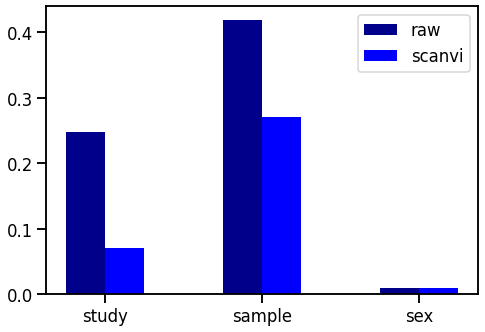

In [69]:
fig = plt.figure()
ax = fig.add_axes([0,0,1,1])
cat = ["study","sample","sex"]
uninteg = [PCR_unintegrated_study,PCR_unintegrated_sample,PCR_unintegrated_sex]
integ=[PCR_integrated_study,PCR_integrated_sample,PCR_integrated_sex]
ax.bar(np.arange(len(cat)),uninteg,color="darkblue",width=0.25,label="raw")
ax.bar(np.arange(len(cat))+0.25,integ,color ="blue",width=0.25,label="scanvi")
plt.xticks([r + 0.125 for r in range(len(cat))], cat)
plt.legend()
plt
plt.show()

## Final accessment - Stabilty

## Biological Metrics

In [8]:
bio_metrics_u=[]
for m in bio_metrics:
    bio_metrics_u.append(m+"_old_params")

In [9]:
filedate1="2022-07-28"#default date format yyyy-mm-dd
results_bio = np.load(f"{workspace}results_biometrics_{filedate1}.npy")
bio_un=np.load(f"{workspace}results_biometrics_2022-07-13.npy")

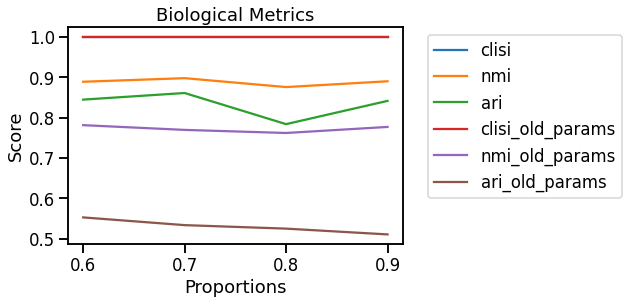

In [26]:
#we plot the pure results of the metrics
plt.plot(np.arange(start,end,step),results_bio[:,0:3],label=bio_metrics[0:3])
plt.plot(np.arange(start,end,step),bio_un[:,0:3],label=bio_metrics_u[0:3])
plt.ylabel("Score")
plt.xlabel("Proportions")
plt.title("Biological Metrics")
#plt.ylim(0.9,1.1)
plt.legend(bbox_to_anchor=(1.05, 1))

In [ ]:
#clisi is 1 in both scenarios excluded anyways

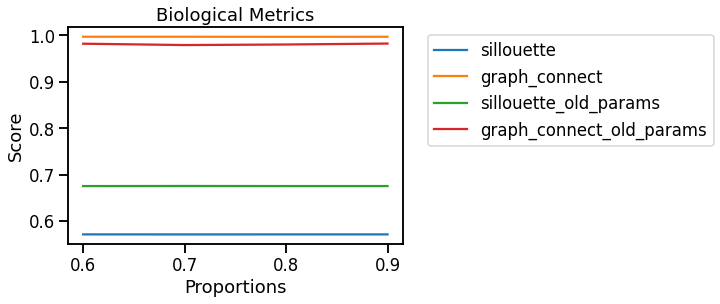

In [27]:
#we plot the pure results of the metrics
plt.plot(np.arange(start,end,step),results_bio[:,3:5],label=bio_metrics[3:5])
plt.plot(np.arange(start,end,step),bio_un[:,3:5],label=bio_metrics_u[3:5])
plt.ylabel("Score")
plt.xlabel("Proportions")
plt.title("Biological Metrics")
plt.legend(bbox_to_anchor=(1.05, 1))

In [21]:
#we plotted the pure results of the metrics
#but this is not sufficent - we want to acess the range of change
#for the metrics to be comparable we want to estimate the change per proportion
dim=int((end-start)/step)
diff_bio=np.zeros((dim,5))

for i in range(1,dim):
    for j in range(5):
        diff_bio[i][j]=np.abs(results_bio[i][j]-results_bio[i-1][j])

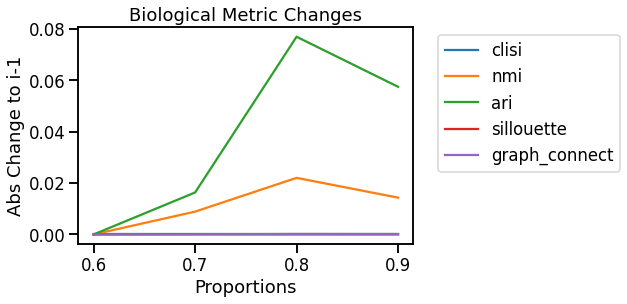

In [22]:
plt.plot(np.arange(start,end,step),diff_bio,label=bio_metrics)
plt.ylabel("Abs Change to i-1")
plt.xlabel("Proportions")
plt.title("Biological Metric Changes")
plt.legend(bbox_to_anchor=(1.05, 1))

## Batchmetrics

In [14]:
filedate2=today#default date format yyyy-mm-dd
results_batch=np.load(f"{workspace}results_batchmetrics_2022-07-31.npy")
batch_un= np.load(f"{workspace}results_batchmetrics_2022-07-19.npy")

In [15]:
batch_metrics_u=[]
for m in batch_metrics:
    batch_metrics_u.append(m+"_old_params")

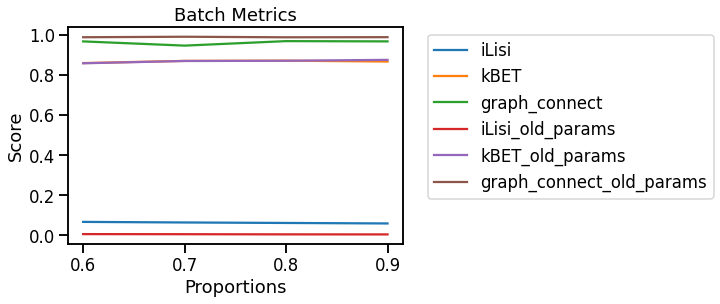

In [31]:
plt.plot(np.arange(start,end,step),results_batch,label=batch_metrics)
plt.plot(np.arange(start,end,step),batch_un,label=batch_metrics_u)
plt.ylabel("Score")
plt.xlabel("Proportions")
plt.title("Batch Metrics")
#plt.ylim(0.9,1)
plt.legend(bbox_to_anchor=(1.05, 1))

In [28]:
dim=int((end-start)/step)
diff_batch=np.zeros((dim,3))

for i in range(1,dim):
    for j in range(3):
        diff_batch[i][j]=np.abs(results_batch[i][j]-results_batch[i-1][j])

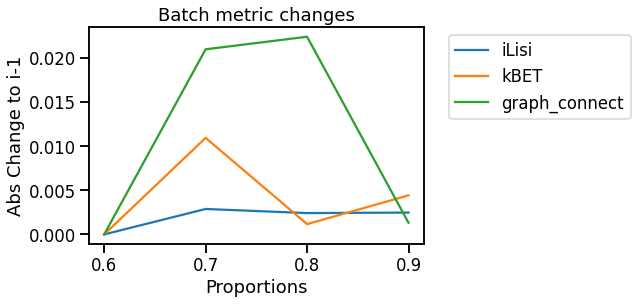

In [29]:
plt.plot(np.arange(start,end,step),diff_batch,label=batch_metrics)
plt.ylabel("Abs Change to i-1")
plt.xlabel("Proportions")
plt.title("Batch metric changes")
plt.legend(bbox_to_anchor=(1.05, 1))

## PCR 

In [41]:
filedate3="2022-07-15"#default date format yyyy-mm-dd
results_PCR = np.load(f"{workspace}PCR_metrics_{filedate3}.npy").T

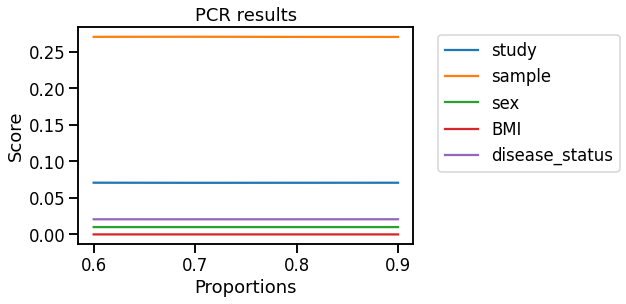

In [42]:
plt.plot(np.arange(start,end,step),results_PCR,label=PCR_cov)
plt.ylabel("Score")
plt.xlabel("Proportions")
plt.title("PCR results")
plt.legend(bbox_to_anchor=(1.05, 1))

In [44]:
dim=int((end-start)/step)
diff_PCR=np.zeros((dim,5))

for i in range(1,dim):
    for j in range(5):
        diff_PCR[i][j]=np.abs(results_PCR[i][j]-results_PCR[i-1][j])

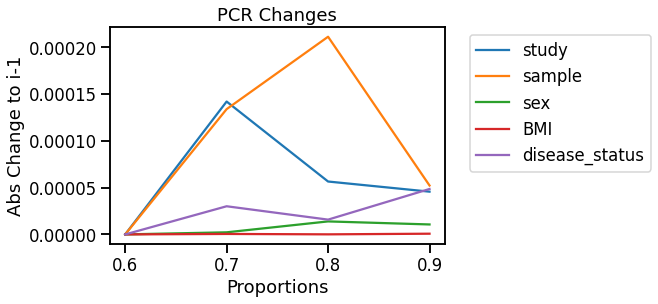

In [45]:
plt.plot(np.arange(start,end,step),diff_PCR,label=PCR_cov)
plt.ylabel("Abs Change to i-1")
plt.xlabel("Proportions")
plt.title("PCR Changes")
plt.legend(bbox_to_anchor=(1.05, 1))

Text(0, 0.5, 'mean change')

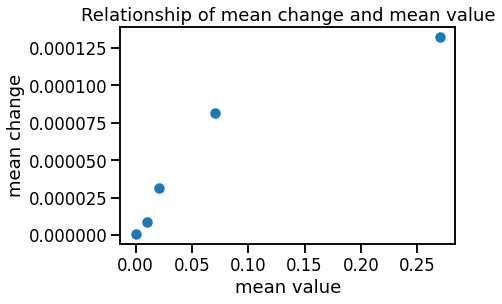

In [58]:
#for PCR the change depends on the mean value
plt.title("Relationship of mean change and mean value")
##we leave out the 0 in the beginning
plt.scatter(np.mean(results_PCR,axis=0),np.mean(diff_PCR[1:],axis=0))
plt.xlabel("mean value")
plt.ylabel("mean change")

## Usability per Celltype/Cluster

In [1]:
bio_metrics = ["clisi","nmi","ari","sillouette","graph_connect"]
batch_metrics=["iLisi","kBET","Graph_connect"]
PCR_cov=['study',"sample","sex","BMI","disease_status"]
usability_bio=["\tIn theory yes but practically useless","\tNo-except for subclustering","\tNo-except for sublcustering","Yes - averaged by group","Yes- averaged by group"]
usability_batch=["\tIn theory computable per subcluster","\tYes-gets computed by label","In theory if computed by cluster"]


In [2]:
print("Biometrics")
for i, j in zip(bio_metrics,usability_bio):
    print(i+"\t"+j)

Biometrics
clisi		In theory yes but practically useless
nmi		No-except for subclustering
ari		No-except for sublcustering
sillouette	Yes - averaged by group
graph_connect	Yes- averaged by group


In [3]:
print("Batchmetrics")
for i, j in zip(batch_metrics,usability_batch):
    print(i+"\t"+j)

Batchmetrics
iLisi		In theory computable per subcluster
kBET		Yes-gets computed by label
Graph_connect	In theory if computed by cluster


In [4]:
print("PCR is usable per cluster/celltype")

PCR is usable per cluster/celltype
